# W4: the real market, SPX 2005–2025

Same question as notebooks 01–03, now on SPX: we sell a one-month ATM call on a real day, hedge it daily to expiry and compare hedging errors. The data is daily SPX from WRDS OptionMetrics (IvyDB); `scripts/prepare_wrds.py` converts it into three CSVs in `data/`:

| File | One row per | Used for |
|---|---|---|
| `history.csv` | trading day: close, 30-day ATM implied volatility, rate, dividend yield | training the generator (W3) and fitting Heston (W2) |
| `options.csv` | option per day (0–70 days to expiry): expiry, strike, bid, ask, implied volatility | premium, both options' IV, second option's prices and spread |
| `surface.csv` | point on the day's IV surface | IV on days the option table does not cover |

`options.csv` covers 0–70 calendar days and strikes within 30% of the index, so both the hedged option and the roughly 60-day option used by the gamma and vega hedges are quoted on almost every day; the remaining days are filled from the surface (README, "Known gaps"). The raw data is not in the repository; its source is cited in the report.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hedging import experiments, generator, hedge, real, worlds

pd.set_option("display.precision", 4)
FIG = experiments.RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
DATA = Path("../data")
history_path, options_path, surface_path = DATA / "history.csv", DATA / "options.csv", DATA / "surface.csv"
print("history:", history_path.exists(), " options:", options_path.exists(), " surface:", surface_path.exists())

history: True  options: True  surface: True


## 1. The history and the fitted models

We split at 70%: data up to mid-2019 is used to fit the generator and Heston, and the hedges are scored on the rest, so no test-period data enters any fit. The left charts show the index and its 30-day IV (dashed line at the split). In the generator's training curve, validation loss turns up after about 300 epochs and we keep the best-validation epoch.

5198 days, 2005-01-03 to 2025-08-29; test from 2019-06-18
StochasticVol(kappa=7.300901098637491, theta=0.03331263642029576, xi=0.5201072397089793, rho=-0.7932237954423998, lam=0.0, mu_j=0.0, sigma_j=0.0)


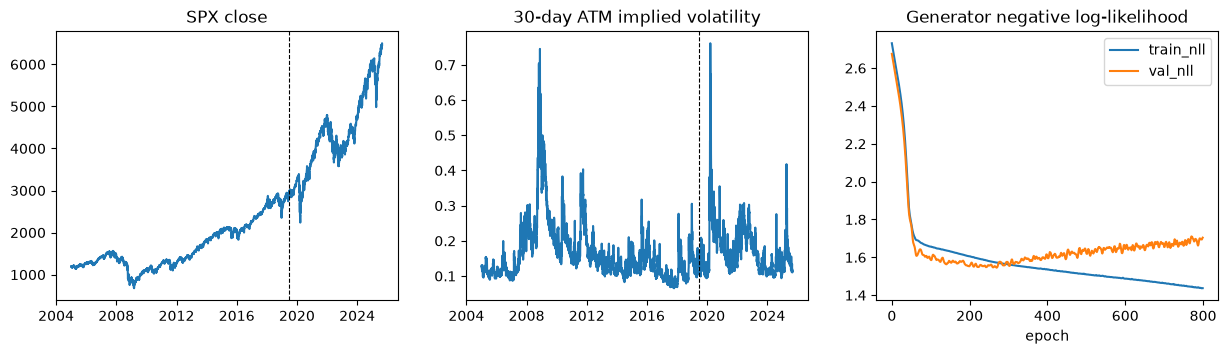

In [2]:
history = real.load_history(history_path)
close, atm_iv = history.close.to_numpy(), history.atm_iv_30d.to_numpy()
cut = int(len(history) * 0.7)  # train on the past only: the test period stays out of every fit
split = history.date[cut]
gen_model, losses = generator.fit(close[:cut], atm_iv[:cut], lr=1e-3, epochs=800)
heston_fit = worlds.calibrate_heston(close[:cut], atm_iv[:cut])
print(f"{len(history)} days, {history.date.iloc[0].date()} to {history.date.iloc[-1].date()}; test from {split.date()}")
print(heston_fit)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(history.date, close); axes[0].set_title("SPX close")
axes[1].plot(history.date, atm_iv); axes[1].set_title("30-day ATM implied volatility")
for ax in axes[:2]:
    ax.axvline(split, color="k", ls="--", lw=.8)
losses.plot(ax=axes[2]); axes[2].set_title("Generator negative log-likelihood"); axes[2].set_xlabel("epoch")
fig.savefig(FIG / "w4_history.png", dpi=150, bbox_inches="tight")

## 2. Stylized facts

Same statistics as in notebook 03, for each world fitted to the training period against the SPX columns. For SPX we expect negative skew, excess kurtosis, volatility clustering and a strongly negative `corr_return_iv_change`.

In [3]:
rng = np.random.default_rng(5)
S_gen, iv_gen = generator.sample(gen_model, close[:cut], atm_iv[:cut], 200, 252, seed=5)
S_h, v_h = heston_fit.simulate(100.0, heston_fit.stationary_variance(200, rng), 1.0, 252, 200, rng)
S_bs = worlds.gbm(100.0, float(atm_iv[:cut].mean()), 1.0, 252, 200, rng)
facts = pd.DataFrame({
    "SPX (train)": generator.stylized_facts(close[:cut], atm_iv[:cut]),
    "SPX (test)": generator.stylized_facts(close[cut:], atm_iv[cut:]),
    "W1 Black-Scholes": generator.stylized_facts(S_bs, np.full_like(S_bs, atm_iv[:cut].mean())),
    "W2 Heston (fitted)": generator.stylized_facts(S_h, np.sqrt(np.maximum(v_h, 1e-8))),
    "W3 generator": generator.stylized_facts(S_gen, iv_gen),
})
experiments.save(facts.reset_index(names="fact"), "w4_stylized_facts")
facts

,SPX (train),SPX (test),W1 Black-Scholes,W2 Heston (fitted),W3 generator
vol_annual,0.1861,0.2077,0.1628,0.1835,0.1819
skew,-0.3655,-0.6580,-0.0116,-0.1509,-0.1251
excess_kurtosis,11.7488,14.7833,0.0140,1.6870,15.3874
acf_abs_return_1,0.2840,0.3809,-0.0047,0.1339,0.1629
acf_abs_return_10,0.3228,0.2888,-0.0093,0.0813,0.0810
corr_return_iv_change,-0.7638,-0.7739,NaN,-0.4518,-0.7727
iv_mean,0.1628,0.1728,0.1628,0.1709,0.1636
iv_change_sd,0.0763,0.0833,0.0000,0.1570,0.0713
acf_iv_change_1,-0.1127,-0.0955,NaN,-0.1871,-0.0875


## 3. Building hedging episodes

Each episode sells the call expiring exactly 21 trading days later with the strike nearest the index and hedges it to expiry. Start days are at least a week apart; before about 2012 SPX had only monthly expiries, so early years have fewer episodes.

Premium (quoted mid), daily index, settlement price and the option's IV on quoted days come from the data. The second option for the gamma and vega hedges has the same strike and the listed expiry nearest 42 trading days, and uses its quoted mid, IV and half spread as cost. The surface fills the few unquoted days, and the few episodes without a suitable listed second option use a model option at exactly 42 days.

Prices are rescaled to strike 100, so an error of 0.5 is 0.5% of the index. The printout gives quote coverage for each option; on start days the surface matches real quotes to about 0.1 vol points.

In [4]:
options = real.load_options(options_path)
surface = real.load_surface(surface_path)
market, info = real.episodes(history, options, surface)
test_rows = np.flatnonzero(info.start >= split)
test, test_info = market.take(test_rows), info.iloc[test_rows].reset_index(drop=True)
print(f"{market.n_paths} episodes, {info.start.min().date()} to {info.expiry.max().date()}; test: {test.n_paths} from {test_info.start.min().date()}")
print("settlement:", info.settlement.value_counts().to_dict())
print(f"half spread: median {info.half_spread.median():.4f}, test {test_info.half_spread.median():.4f}")
print(f"second option half spread: median {info.half_spread2.median():.4f}, test {test_info.half_spread2.median():.4f}")
print(f"days with the option's own quote: {info.quoted.mean():.1%}; the second option's: {info.quoted2.mean():.1%} "
      f"(test {test_info.quoted2.mean():.1%}); episodes with no listed second option: {(info.quoted2 == 0).sum()}")
print(f"quoted iv - surface iv at the start: median {(info.iv_quoted - info.iv_surface).median():.4f}")
info.groupby(info.start.dt.year).agg(episodes=("start", "size"), iv=("iv_quoted", "mean"), half_spread=("half_spread", "median"),
                                  half_spread2=("half_spread2", "median"), quoted2=("quoted2", "mean"))

721 episodes, 2005-01-20 to 2025-08-27; test: 291 from 2019-06-20
settlement: {'PM': 578, 'AM': 143}
half spread: median 0.0105, test 0.0038
second option half spread: median 0.0084, test 0.0028
days with the option's own quote: 94.2%; the second option's: 96.5% (test 98.5%); episodes with no listed second option: 24
quoted iv - surface iv at the start: median -0.0014


,episodes,iv,half_spread,half_spread2,quoted2
start,,,,,
2005,12,0.1143,0.0323,0.0357,0.7500
2006,12,0.1127,0.0377,0.0332,0.9167
2007,16,0.1577,0.0326,0.0277,0.8125
2008,16,0.3145,0.0317,0.0231,0.8665
2009,16,0.2794,0.0301,0.0274,0.8750
2010,16,0.1966,0.0498,0.0415,0.9375
2011,16,0.2155,0.0392,0.0290,0.9972
2012,30,0.1549,0.0314,0.0326,0.9333
2013,45,0.1243,0.0187,0.0223,0.9091


## 4. Classical hedges on all episodes, 2005–2025

Classical strategies rebalanced daily at 0, 1, 5 and 10 bp per index trade. Nothing is trained, so we use all 20 years. RMSE is in % of the index; the bottom row is the unhedged benchmark.

In [5]:
tables = []
for bp in experiments.COSTS_BP:
    chosen = {"unhedged": hedge.unhedged, **hedge.classical(bp / 1e4)}
    tables.append(hedge.evaluate(market, chosen, bp / 1e4, info.half_spread2.to_numpy() if bp else 0.0,
                                 world="W4 SPX", cost_bp=bp))
classical = experiments.save(pd.concat(tables, ignore_index=True), "w4_classical")
classical.pivot(index="strategy", columns="cost_bp", values="rmse")

cost_bp,0,1,5,10
strategy,,,,
delta,0.5986,0.5949,0.5917,0.6130
delta_gamma,0.5376,0.7110,0.7843,0.8943
delta_vega,0.3357,0.3486,0.3710,0.4245
leland,NaN,0.5959,0.5964,0.6203
unhedged,2.3083,2.3083,2.3083,2.3083
whalley_wilmott,NaN,0.6058,0.6256,0.6568


## 5. Which world should a hedger learn in?

As in notebook 03, deep hedgers are trained in each world fitted to the training period and everything is scored on the real test episodes (daily, 5 bp); green bars are deep hedgers. "Reference (simulated)" is notebook 03's market; it is no longer an upper bound here, just another training world.

In [6]:
train = experiments.training_worlds(close[:cut], atm_iv[:cut], gen_model)
scores, errors, policies = experiments.transfer(train, test, cost_option=test_info.half_spread2.to_numpy())
scores["strategy"] = scores.strategy.str.replace("Reference (upper bound)", "Reference (simulated)")
errors.columns = scores.strategy.to_list()
experiments.save(scores, "w4_transfer")
experiments.save(errors, "w4_test_errors")
scores

,strategy,rmse,cvar95,mean,std,turnover
0,delta,0.6368,1.9403,-0.0773,0.6321,2.5384
1,delta_gamma,0.5893,1.4644,-0.2709,0.5233,3.0340
2,delta_vega,0.3570,1.0460,-0.1101,0.3396,2.1030
3,leland,0.6425,1.9593,-0.0798,0.6375,2.5126
4,whalley_wilmott,0.6384,1.9048,-0.0310,0.6376,1.8130
5,deep (W1 Black-Scholes),0.6953,2.0812,-0.0838,0.6902,2.3548
6,deep (W2 Heston (fitted)),0.6264,1.7999,-0.1109,0.6165,2.2882
7,deep (W3 generator),0.5354,1.5161,-0.1422,0.5162,2.1381
8,deep (Reference (simulated)),0.8067,2.0119,-0.1806,0.7862,1.9428


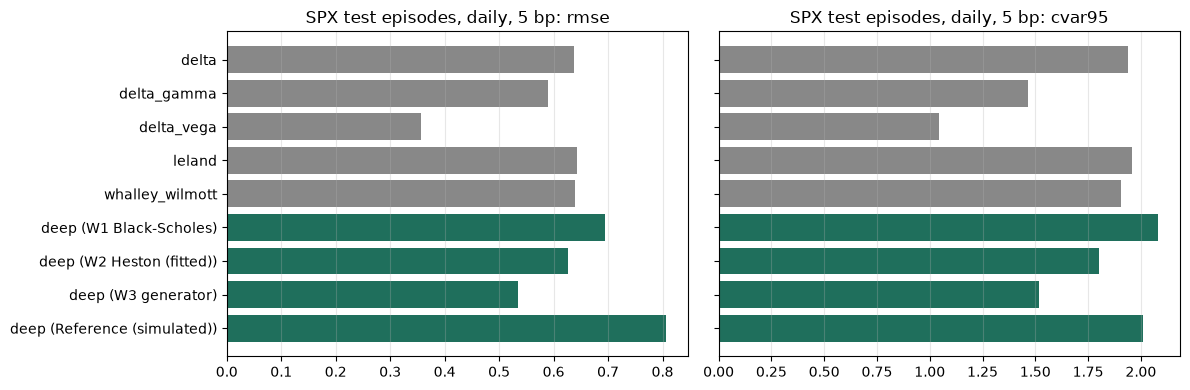

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col in zip(axes, ["rmse", "cvar95"]):
    ax.barh(scores.strategy, scores[col], color=["#888"] * 5 + ["#1f6f5c"] * 4)
    ax.set_title(f"SPX test episodes, daily, 5 bp: {col}"); ax.grid(axis="x", alpha=.3)
axes[0].invert_yaxis()
fig.tight_layout()
fig.savefig(FIG / "w4_transfer.png", dpi=150, bbox_inches="tight")

## 6. Block bootstrap

Differences in RMSE and CVaR 95% against BS delta (and deep hedgers against the W2-trained one), with 95% intervals; an interval containing 0 means no significant difference. Episodes start a week apart but last a month, so neighbours share most of their days and are not independent. We therefore resample blocks of 5 consecutive episodes (about one option's life), which widens the intervals.

In [8]:
BLOCK = 5  # consecutive episodes resampled together: they overlap in time
ci = pd.concat([experiments.paired_bootstrap(errors, "delta", block=BLOCK),
                experiments.paired_bootstrap(errors[[c for c in errors if c.startswith("deep")]], "deep (W2 Heston (fitted))",
                                             block=BLOCK)],
               ignore_index=True)
ci["rmse_differs"] = (ci.d_rmse_hi < 0) | (ci.d_rmse_lo > 0)
experiments.save(ci, "w4_bootstrap")
ci

,strategy,vs,d_rmse,d_rmse_lo,d_rmse_hi,d_cvar95,d_cvar95_lo,d_cvar95_hi,rmse_differs
0,delta_gamma,delta,-0.0475,-0.1825,0.0954,-0.4759,-1.2337,0.3225,False
1,delta_vega,delta,-0.2798,-0.4354,-0.1508,-0.8943,-1.5901,-0.3232,True
2,leland,delta,0.0057,-0.0002,0.0111,0.0190,-0.0127,0.0453,False
3,whalley_wilmott,delta,0.0016,-0.0528,0.0631,-0.0355,-0.3604,0.2078,False
4,deep (W1 Black-Scholes),delta,0.0585,0.0295,0.0878,0.1409,-0.0088,0.2884,True
5,deep (W2 Heston (fitted)),delta,-0.0104,-0.0610,0.0358,-0.1404,-0.2661,0.0676,False
6,deep (W3 generator),delta,-0.1014,-0.2073,0.0025,-0.4242,-0.8509,-0.0593,False
7,deep (Reference (simulated)),delta,0.1699,0.0511,0.2798,0.0716,-0.3650,0.6181,True
8,deep (W1 Black-Scholes),deep (W2 Heston (fitted)),0.0689,0.0356,0.1082,0.2813,0.1230,0.3469,True
9,deep (W3 generator),deep (W2 Heston (fitted)),-0.0910,-0.2278,0.0208,-0.2838,-0.9072,0.1000,False


## 7. Error decomposition on real data

Same decomposition as notebook 03: 5-minute BS delta in the textbook world, then daily rebalancing, then costs, then real SPX. Each bar is the increment from that step.

,step,rmse,cvar95,mean,std,turnover
0,"Continuous (5-minute, W1)",0.0412,0.0941,1.6666e-05,0.0412,13.8748
1,+ Discrete (daily),0.3475,0.8085,-6.9828e-04,0.3475,2.4294
2,+ Costs,0.3746,0.9622,-1.2217e-01,0.3542,2.4294
3,+ Misspecification (SPX),0.6368,1.9403,-7.7312e-02,0.6321,2.5384


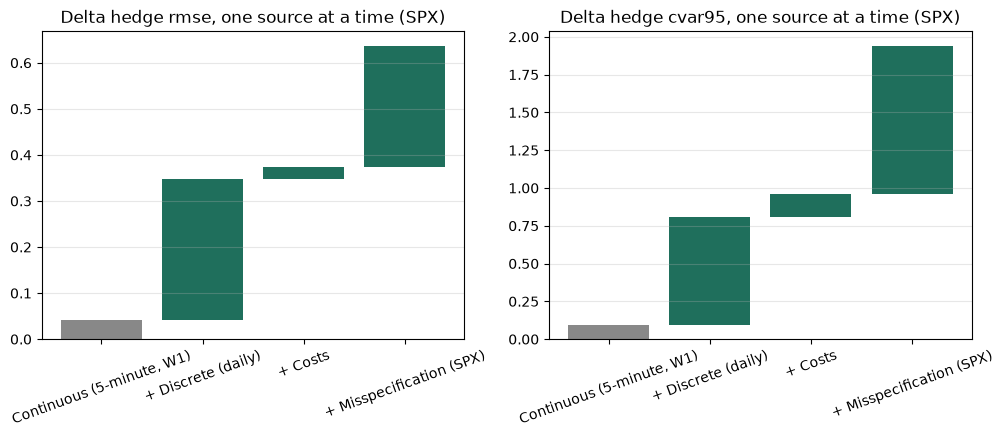

In [9]:
steps = experiments.decomposition(test, sigma=float(atm_iv[:cut].mean()))
steps["step"] = steps.step.str.replace("test market", "SPX")
experiments.save(steps, "w4_error_decomposition")
display(steps)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["rmse", "cvar95"]):
    v = steps[col].to_numpy()
    bottoms = np.r_[0, v[:-1]]
    ax.bar(steps.step, v - bottoms, bottom=bottoms, color=["#888"] + ["#1f6f5c"] * (len(v) - 1))
    ax.set_title(f"Delta hedge {col}, one source at a time (SPX)"); ax.tick_params(axis="x", rotation=20); ax.grid(axis="y", alpha=.3)
fig.savefig(FIG / "w4_error_decomposition.png", dpi=150, bbox_inches="tight")